# 🛒 Análise de Vendas de um E-commerce

Estudo de caso de análise de dados usando **Python** e **SQL**, seguindo a metodologia **CRISP-DM**.

## Índice

1. Entendimento do Negócio e Contextualização
2. Bibliotecas Utilizadas
3. Carregamento dos Dados
4. Descrição dos Dados
5. Limpeza e Preparação dos Dados
6. Análise dos Dados
7. Conclusões e Recomendações
8. Deploy: Como Reproduzir este Projeto

# 1- Entendimento do Negócio e Contextualização

## A história da Vitrine Brasil

Tudo começou em 2022, na garagem de uma casa em Campinas (SP). A Marina e o Rafael, um casal que adorava garimpar promoções, começaram vendendo fones de ouvido e acessórios de celular pela internet. Os primeiros pedidos eram embalados na mesa da cozinha e despachados nos Correios.

Deu tão certo que nasceu a **Vitrine Brasil**, uma loja online que hoje vende para o país inteiro. O catálogo cresceu e agora tem produtos de cinco categorias: **Eletrônicos, Casa, Moda, Esporte e Beleza**.

Com o crescimento, apareceu um problema: **as decisões eram tomadas no "feeling"**. O estoque era comprado por intuição, o dinheiro de marketing era dividido meio no chute e ninguém sabia dizer com certeza quais produtos davam lucro e quais só ocupavam espaço no armazém.

Com a Black Friday de 2026 chegando, a diretoria resolveu contratar uma pessoa para analisar os dados de vendas e ajudar a decidir **onde investir em marketing e estoque**.

Esse alguém é você, o(a) analista de dados. 🚀

## Problema de negócio

> **Onde está o dinheiro da Vitrine Brasil e como usar isso para planejar o próximo ano?**

## Perguntas que a análise vai responder

1. Quais **categorias e produtos** geram mais receita?
2. Como as **vendas variam mês a mês** (existe sazonalidade)?
3. Quais **estados** compram mais?
4. Qual o **ticket médio** (valor médio gasto por pedido)?
5. Quantos clientes compram **só uma vez** e quantos **voltam a comprar**?

## Objetivo do projeto

Transformar os dados de vendas de 2025 em respostas claras para a diretoria, apontando recomendações práticas de marketing e estoque.

## Sobre os dados

Os dados deste projeto são **fictícios**. Eles foram gerados por um script (`generate_data.py`) justamente para simular a rotina de uma empresa real, incluindo problemas comuns como valores nulos e registros duplicados. Qualquer semelhança com empresas reais é coincidência.

## Ferramentas

- **Python** (pandas, matplotlib e seaborn)
- **SQL** (SQLite)
- **Jupyter Notebook**
- **Git** para versionamento

## Estrutura do projeto

```
ecommerce-sales-analysis/
├── .gitignore
├── requirements.txt
├── generate_data.py
├── customers.csv
├── products.csv
├── orders.csv
├── order_items.csv
└── ecommerce_analysis.ipynb
```

| Arquivo | Para que serve |
|---|---|
| `generate_data.py` | Gera as bases fictícias em CSV |
| `customers.csv` | Dados dos clientes |
| `products.csv` | Catálogo de produtos |
| `orders.csv` | Pedidos realizados |
| `order_items.csv` | Itens de cada pedido |
| `requirements.txt` | Bibliotecas necessárias para reproduzir o projeto |
| `ecommerce_analysis.ipynb` | Este notebook, com toda a análise |

# 2- Bibliotecas Utilizadas

Aqui ficam todas as bibliotecas que o projeto usa. Deixar tudo importado no começo do notebook ajuda quem for reproduzir a análise a ver rapidinho o que precisa ter instalado.

| Biblioteca | Para que serve neste projeto |
|---|---|
| `pandas` | Carregar, limpar e analisar as tabelas |
| `sqlite3` | Rodar consultas SQL dentro do notebook (já vem com o Python) |
| `matplotlib` | Criar os gráficos |
| `seaborn` | Deixar os gráficos mais bonitos e fáceis de montar |

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 3- Carregamento dos Dados

A Vitrine Brasil entregou os dados de vendas de 2025 em **quatro arquivos CSV**, que se relacionam entre si:

| Arquivo | Conteúdo | Chave de ligação |
|---|---|---|
| `customers.csv` | Clientes da loja | `customer_id` |
| `products.csv` | Catálogo de produtos | `product_id` |
| `orders.csv` | Pedidos realizados | `order_id` e `customer_id` |
| `order_items.csv` | Produtos e quantidades de cada pedido | `order_id` e `product_id` |

Vamos carregar cada arquivo em um DataFrame do pandas. As colunas de data já são lidas como data, para facilitar as análises por período.

In [2]:
customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
products = pd.read_csv('products.csv')
orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
order_items = pd.read_csv('order_items.csv')

In [3]:
print('customers:', customers.shape)
print('products:', products.shape)
print('orders:', orders.shape)
print('order_items:', order_items.shape)

customers: (1020, 4)
products: (50, 4)
orders: (5030, 4)
order_items: (8676, 3)


# 4- Descrição dos Dados

Antes de limpar ou analisar, precisamos **conhecer os dados**: como as tabelas são, quais colunas existem e de que tipo é cada uma.

## 4.1 Dicionário de dados

| Tabela | Coluna | Descrição |
|---|---|---|
| `customers` | `customer_id` | Código único do cliente |
| `customers` | `customer_name` | Nome do cliente |
| `customers` | `state` | Estado (UF) do cliente |
| `customers` | `signup_date` | Data de cadastro |
| `products` | `product_id` | Código único do produto |
| `products` | `product_name` | Nome do produto |
| `products` | `category` | Categoria do produto |
| `products` | `unit_price` | Preço unitário em reais |
| `orders` | `order_id` | Código único do pedido |
| `orders` | `customer_id` | Cliente que fez o pedido |
| `orders` | `order_date` | Data do pedido |
| `orders` | `status` | Situação do pedido (Entregue, Cancelado ou Devolvido) |
| `order_items` | `order_id` | Pedido ao qual o item pertence |
| `order_items` | `product_id` | Produto comprado |
| `order_items` | `quantity` | Quantidade comprada |

## 4.2 Primeiras linhas de cada tabela

In [4]:
display(customers.head())
display(products.head())
display(orders.head())
display(order_items.head())

,customer_id,customer_name,state,signup_date
0,1,Diego Silva,CE,2024-05-10
1,2,Isabela Souza,PR,2024-12-31
2,3,Hugo Oliveira,SP,2024-11-10
3,4,Diego Almeida,SP,2022-05-02
4,5,Carla Carvalho,MG,2023-04-12


,product_id,product_name,category,unit_price
0,1,Fone de Ouvido Bluetooth,Eletrônicos,1414.85
1,2,Carregador Portátil,Eletrônicos,88.90
2,3,Smartwatch,Eletrônicos,1278.25
3,4,Caixa de Som,Eletrônicos,1319.95
4,5,Mouse Sem Fio,ELETRÔNICOS,347.90


,order_id,customer_id,order_date,status
0,1,84,2025-01-01,Entregue
1,2,950,2025-01-01,Entregue
2,3,164,2025-01-01,Entregue
3,4,603,2025-01-01,Cancelado
4,5,299,2025-01-01,Entregue


,order_id,product_id,quantity
0,1,50,1
1,1,19,2
2,2,1,2
3,3,12,1
4,3,21,1


## 4.3 Tipos de dados de cada coluna

In [5]:
customers.info()
print('\n')
products.info()
print('\n')
orders.info()
print('\n')
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customer_id    1020 non-null   int64         
 1   customer_name  1020 non-null   str           
 2   state          990 non-null    str           
 3   signup_date    1020 non-null   datetime64[us]
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 32.0 KB


<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    50 non-null     int64  
 1   product_name  50 non-null     str    
 2   category      50 non-null     str    
 3   unit_price    50 non-null     float64
dtypes: float64(1), int64(1), str(2)
memory usage: 1.7 KB


<class 'pandas.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 4 columns):
 #   Column       Non-Null 

## 4.4 Valores nulos

Primeiro, quantos valores vazios existem em cada coluna.

In [6]:
print(customers.isnull().sum())
print('\n')
print(products.isnull().sum())
print('\n')
print(orders.isnull().sum())
print('\n')
print(order_items.isnull().sum())

customer_id       0
customer_name     0
state            30
signup_date       0
dtype: int64


product_id      0
product_name    0
category        0
unit_price      0
dtype: int64


order_id         0
customer_id      0
order_date       0
status         100
dtype: int64


order_id      0
product_id    0
quantity      0
dtype: int64


## 4.5 Linhas duplicadas

Agora, quantas linhas estão repetidas em cada tabela.

In [7]:
print('customers:', customers.duplicated().sum())
print('products:', products.duplicated().sum())
print('orders:', orders.duplicated().sum())
print('order_items:', order_items.duplicated().sum())

customers: 20
products: 0
orders: 30
order_items: 0


## 4.6 Textos escritos de formas diferentes

Para colunas de categoria, o ideal é ter cada valor escrito de **um único jeito**. Vamos olhar os valores únicos de `state` e `category`.

In [8]:
print(customers['state'].unique())
print('\n')
print(products['category'].unique())

<StringArray>
['CE', 'PR', 'SP', 'MG',  nan, 'SC', 'RS', 'BA', 'RJ', 'sp', 'GO', 'ce', 'PE',
 'mg', 'rj', 'pr', 'sc', 'pe', 'rs', 'ba']
Length: 20, dtype: str


<StringArray>
[ 'Eletrônicos',  'ELETRÔNICOS', 'Eletrônicos ',         'Casa',
         'CASA',        'Casa ',         'Moda',        'Moda ',
      'Esporte',     'Esporte ',       'Beleza',       'BELEZA']
Length: 12, dtype: str


## 4.7 Datas fora do período

Os pedidos são de 2025. Vamos conferir os anos que aparecem na coluna `order_date`.

In [9]:
print(orders['order_date'].dt.year.value_counts())

order_date
2025    5015
2035      15
Name: count, dtype: int64


## 4.8 Resumo dos problemas encontrados

| Tabela | Problema | O que fazer na limpeza |
|---|---|---|
| `customers` | Estados vazios | Preencher com `'Não informado'` |
| `customers` | Estados em minúsculo | Padronizar em maiúsculo |
| `customers` | Linhas duplicadas | Remover as repetições |
| `products` | Categorias em maiúsculo ou com espaço sobrando | Padronizar a escrita |
| `orders` | Status vazio | Preencher com `'Não informado'` |
| `orders` | Datas em 2035 (fora de 2025) | Corrigir o ano para 2025 |
| `orders` | Linhas duplicadas | Remover as repetições |
| `order_items` | Nenhum problema encontrado | Manter como está |

Com esse mapa em mãos, a limpeza na próxima seção fica direta ao ponto: cada problema encontrado aqui tem uma solução prevista.

# 5- Limpeza e Preparação dos Dados

Nesta etapa, cada problema encontrado na seção 4 recebe uma correção. Depois de cada uma, conferimos o resultado para ter certeza de que deu certo.

## 5.1 Limpeza da tabela `customers`

Correções desta tabela:
- Padronizar os estados em maiúsculo (`sp` vira `SP`)
- Preencher os estados vazios com `'Não informado'`
- Remover as linhas duplicadas

In [10]:
customers['state'] = customers['state'].str.upper()
customers['state'] = customers['state'].fillna('Não informado')
customers = customers.drop_duplicates().reset_index(drop=True)

In [11]:
print(customers.shape)
print(customers.duplicated().sum())
print(customers['state'].unique())

(1000, 4)
0
<StringArray>
['CE', 'PR', 'SP', 'MG', 'Não informado', 'SC', 'RS', 'BA', 'RJ', 'GO', 'PE']
Length: 11, dtype: str


## 5.2 Limpeza da tabela `products`

Correção desta tabela:
- Padronizar as categorias: tirar espaços sobrando e deixar só a primeira letra maiúscula (`ELETRÔNICOS` vira `Eletrônicos` e `'Casa '` vira `'Casa'`)

In [12]:
products['category'] = products['category'].str.strip().str.title()
print(products['category'].value_counts())

category
Eletrônicos    10
Casa           10
Moda           10
Esporte        10
Beleza         10
Name: count, dtype: int64


## 5.3 Limpeza da tabela `orders`

Correções desta tabela:
- Remover as linhas duplicadas
- Corrigir as datas em 2035, trocando o ano para 2025. A suposição é de erro de digitação no ano, já que o dia e o mês continuam plausíveis e 2035 está no futuro
- Preencher os status vazios com `'Não informado'`

In [13]:
orders = orders.drop_duplicates().reset_index(drop=True)

wrong_year = orders['order_date'].dt.year == 2035

orders.loc[wrong_year, 'order_date'] = orders.loc[wrong_year, 'order_date'] - pd.DateOffset(years=10)

orders['status'] = orders['status'].fillna('Não informado')

In [14]:
print(orders.shape)
print(orders.duplicated().sum())
print(orders['order_date'].dt.year.value_counts())
print(orders['status'].value_counts())

(5000, 4)
0
order_date
2025    5000
Name: count, dtype: int64
status
Entregue         4276
Cancelado         422
Devolvido         202
Não informado     100
Name: count, dtype: int64


## 5.4 Criação do banco de dados SQLite

Com os dados limpos, vamos criar um banco **SQLite** com as quatro tabelas. Assim, as perguntas de negócio podem ser respondidas com **SQL** e com **Python**, como acontece no dia a dia de um analista.

O banco é criado **na memória**: ele existe enquanto o notebook está aberto e é montado de novo a cada execução. Por isso não gera nenhum arquivo extra e o projeto continua simples de reproduzir.

In [17]:
# Criando o banco
conn = sqlite3.connect(':memory:')

customers.to_sql('customers', conn, index=False)
products.to_sql('products', conn, index=False)
orders.to_sql('orders', conn, index=False)
order_items.to_sql('order_items', conn, index=False)

# Conferindo o banco
query = '''
SELECT name
FROM sqlite_master
WHERE type = 'table'
'''

display(pd.read_sql(query, conn))

query = '''
SELECT COUNT(*) AS total_orders
FROM orders
'''

display(pd.read_sql(query, conn))

,name
0,customers
1,products
2,orders
3,order_items


,total_orders
0,5000


# 6- Análise dos Dados

Nesta etapa, cada pergunta de negócio da seção 1 é respondida com **SQL** e visualizada com **Python**.

## Como a receita é calculada

- **Receita** = quantidade comprada x preço unitário do produto
- Só entram os pedidos com status **Entregue**. Pedidos cancelados e devolvidos não geram receita, e os pedidos com status `'Não informado'` ficam de fora porque não dá para confirmar a entrega. É uma escolha conservadora, para não superestimar o faturamento.

## 6.1 Quais categorias geram mais receita?

In [19]:
query = '''
SELECT p.category,
       ROUND(SUM(oi.quantity * p.unit_price), 2) AS revenue
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
JOIN products p ON oi.product_id = p.product_id
WHERE o.status = 'Entregue'
GROUP BY p.category
ORDER BY revenue DESC
'''

revenue_by_category = pd.read_sql(query, conn)
display(revenue_by_category)

,category,revenue
0,Eletrônicos,1505007.61
1,Casa,730116.28
2,Esporte,650245.71
3,Moda,478745.68
4,Beleza,393170.37


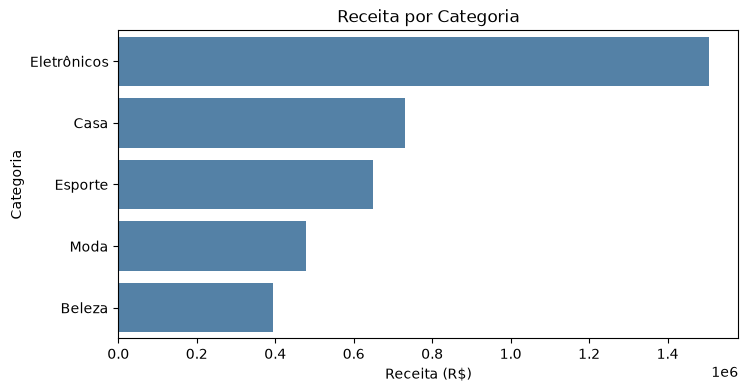

In [20]:
plt.figure(figsize=(8,4))
sns.barplot(data=revenue_by_category, x='revenue', y='category', color='steelblue')
plt.title('Receita por Categoria')
plt.xlabel('Receita (R$)')
plt.ylabel('Categoria')
plt.show()

### Observações

- **Eletrônicos** é a categoria que mais gera receita para a Vitrine Brasil.
- **Beleza** é a categoria que menos gera receita.
- Uma possível explicação é o **preço dos produtos**: itens como smartwatch, tablet e Smart TV têm valor unitário bem mais alto do que os produtos de beleza. Ainda assim, essa é uma hipótese, porque a análise até aqui olhou só a receita total, e não a quantidade de unidades vendidas.

### Recomendação

Eletrônicos merece atenção especial no estoque e no marketing da Black Friday, já que é onde está a maior fatia do faturamento. Já Beleza pode ser tratada como uma categoria de apoio, com investimentos mais pontuais.

> **Atenção:** receita não é lucro. Uma categoria com muita receita pode ter margem baixa, mas essa informação não existe na base e fica como sugestão de próximo passo.

## 6.2 Quais produtos geram mais receita?

Aqui vamos olhar os **10 produtos** que mais faturam. A regra da receita é a mesma da seção anterior: só pedidos com status **Entregue**.

In [21]:
query = '''
SELECT p.product_name,
       p.category,
       ROUND(SUM(oi.quantity * p.unit_price),2) AS revenue
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
JOIN products p ON oi.product_id = p.product_id
WHERE o.status = 'Entregue'
GROUP BY p.product_id, p.product_name, p.category
ORDER BY revenue DESC
LIMIT 10
'''

top_products = pd.read_sql(query, conn)
display(top_products)

,product_name,category,revenue
0,Fone de Ouvido Bluetooth,Eletrônicos,881451.55
1,Toalha de Banho,Casa,365404.17
2,Sérum Facial,Beleza,217732.20
3,Smart TV 43,Eletrônicos,184559.65
4,Bicicleta Ergométrica,Esporte,170435.36
5,Garrafa Esportiva,Esporte,147993.45
6,Bolsa de Ombro,Moda,137318.33
7,Smartwatch,Eletrônicos,115042.50
8,Webcam Full HD,Eletrônicos,111621.30
9,Luminária de Mesa,Casa,101642.73


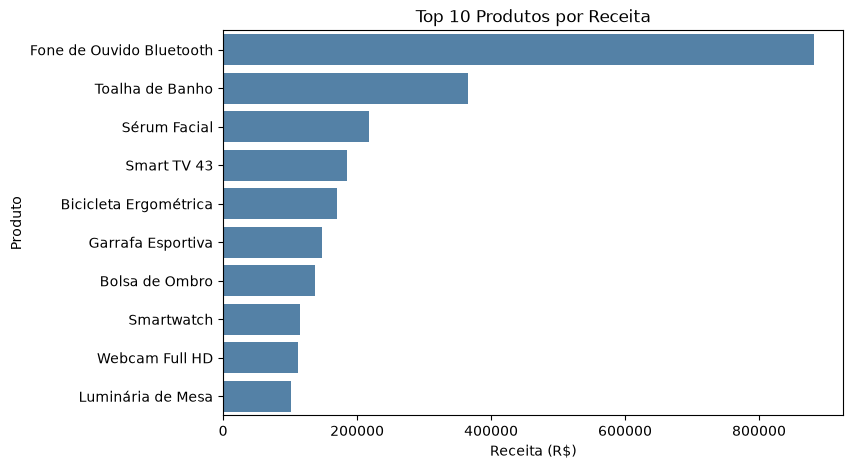

In [23]:
plt.figure(figsize=(8, 5))
sns.barplot(data=top_products, x='revenue', y='product_name', color='steelblue')
plt.title('Top 10 Produtos por Receita')
plt.xlabel('Receita (R$)')
plt.ylabel('Produto')
plt.show()

### Observações

- O produto que mais gera receita é o **Fone de Ouvido Bluetooth**, da categoria **Eletrônicos**.
- Receita alta pode vir de **muitas unidades vendidas** ou de um **preço alto**. Esta análise não separa os dois motivos.

### Recomendação

Garantir estoque dos produtos do top 10 antes da Black Friday, começando pelo Fone de Ouvido Bluetooth, para não perder vendas por falta de produto.

## 6.3 Como as vendas variam mês a mês?

Aqui vamos somar a receita de cada mês de 2025, para descobrir se existem períodos mais fortes e mais fracos. A regra da receita continua a mesma: só pedidos com status **Entregue**.

In [26]:
query = '''
SELECT strftime('%Y-%m', o.order_date) AS month,
       ROUND(SUM(oi.quantity * p.unit_price), 2) AS revenue
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
JOIN products p ON oi.product_id = p.product_id
WHERE o.status = 'Entregue'
GROUP BY month
ORDER BY month
'''

monthly_revenue = pd.read_sql(query, conn)
display(monthly_revenue)

,month,revenue
0,2025-01,224240.78
1,2025-02,205472.10
2,2025-03,257328.15
3,2025-04,270473.67
4,2025-05,277526.91
5,2025-06,285505.62
6,2025-07,264274.39
7,2025-08,282339.63
8,2025-09,296481.80
9,2025-10,337922.56


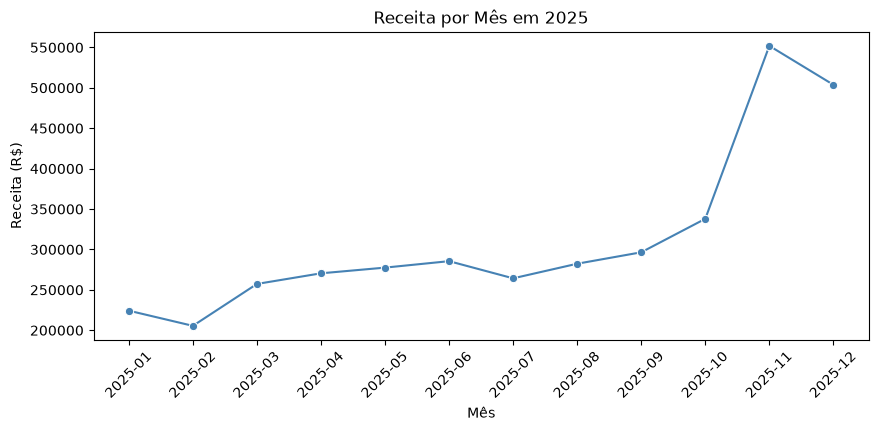

In [27]:
plt.figure(figsize=(10, 4))
sns.lineplot(data=monthly_revenue, x='month', y='revenue', marker='o', color='steelblue')
plt.title('Receita por Mês em 2025')
plt.xlabel('Mês')
plt.ylabel('Receita (R$)')
plt.xticks(rotation=45)
plt.show()

### Observações

- **Novembro de 2025** foi o mês de maior receita e **fevereiro de 2025** foi o de menor receita.
- A receita fica mais estável durante boa parte do ano e cresce no fim, perto de novembro e dezembro.
- Uma possível explicação para o pico de novembro é a **Black Friday**, e o movimento de dezembro pode estar ligado ao **Natal**. É uma hipótese, porque a base não traz informação sobre campanhas ou promoções.

### Recomendação

Planejar estoque e marketing com antecedência para o fim do ano, já que é o período de maior faturamento. Fevereiro, por ser o mês mais fraco, pode ser uma oportunidade para ações de incentivo à compra.

## 6.4 Quais estados compram mais?

Aqui vamos somar a receita por estado do cliente. A regra da receita continua a mesma: só pedidos com status **Entregue**.

Os clientes que estavam sem estado na base aparecem como `'Não informado'`.

In [28]:
query = '''
SELECT c.state,
       ROUND(SUM(oi.quantity * p.unit_price), 2) AS revenue
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
JOIN products p ON oi.product_id = p.product_id
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.status = 'Entregue'
GROUP BY c.state
ORDER BY revenue DESC
'''

revenue_by_state = pd.read_sql(query, conn)
display(revenue_by_state)

,state,revenue
0,SP,1073476.36
1,RJ,696740.65
2,MG,589263.51
3,PR,296907.27
4,RS,287993.41
5,BA,216755.17
6,SC,179341.60
7,PE,133836.86
8,CE,130629.38
9,GO,85472.30


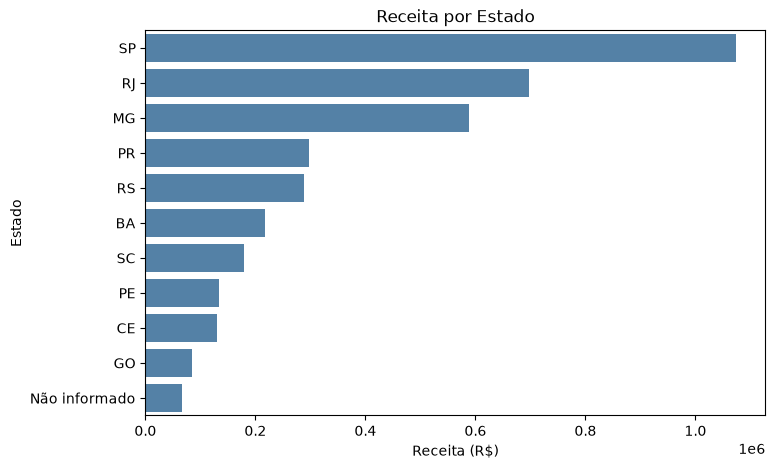

In [29]:
plt.figure(figsize=(8, 5))
sns.barplot(data=revenue_by_state, x='revenue', y='state', color='steelblue')
plt.title('Receita por Estado')
plt.xlabel('Receita (R$)')
plt.ylabel('Estado')
plt.show()

### Observações

- **São Paulo (SP)** é o estado que mais gera receita e **Goiás (GO)** é o que menos gera, entre os estados informados.
- Uma possível explicação é o **tamanho da base de clientes** em cada estado: quanto mais clientes, maior tende a ser a receita. É uma hipótese, porque esta análise olhou só a receita total, sem separar quantos clientes existem em cada estado nem quanto cada um gasta.

### Recomendação

Manter São Paulo como prioridade em marketing e logística, já que concentra a maior parte do faturamento. Para os estados com menor receita, como Goiás, vale testar ações pontuais, como frete reduzido, antes de investir pesado.

## 6.5 Qual o ticket médio?

O **ticket médio** é o valor médio gasto em cada pedido. Primeiro calculamos o valor de cada pedido e depois tiramos a média. A regra da receita continua a mesma: só pedidos com status **Entregue**.

In [30]:
query = '''
WITH order_revenue AS (
    SELECT o.order_id,
           SUM(oi.quantity * p.unit_price) AS revenue
    FROM order_items oi
    JOIN orders o ON oi.order_id = o.order_id
    JOIN products p ON oi.product_id = p.product_id
    WHERE o.status = 'Entregue'
    GROUP BY o.order_id
)
SELECT COUNT(*) AS total_orders,
       ROUND(AVG(revenue), 2) AS average_ticket
FROM order_revenue
'''

average_ticket = pd.read_sql(query, conn)
display(average_ticket)

,total_orders,average_ticket
0,4276,878.69
